# C3 · Final views with the shared visual system
## Formula 1 World Championship, 2014–2024 — the charts used in the final presentation

**Business Intelligence · IIB423T-1 · Universidad del Desarrollo** — **Group 06**: Maximiliano Sandoval Mosser and
Benjamín Toloza Cossio · Instructor: Tomás Fontecilla · November 2026

**Purpose.** This notebook draws the five charts of the final presentation with **one shared set of visual rules**
(`analysis/visual_system.py`). It does not train a model or touch row-level data: every value comes from the saved
results of `notebooks/final_project.ipynb` (`data/processed/final_key_numbers.json` and
`data/processed/final_validation_by_season.csv`), and the first code cell checks them against the numbers printed there.

| Figure | Slide | Task of the reader (action + target) | Design origin |
|---|---|---|---|
| `C3_01_points_by_grid_block` | The grid already tells most of the story | **Compare** the share of starters who score points across grid blocks | Max's C1/final chart, neutral color |
| `C3_02_f1_by_season` | The model is slightly better, not every season | **Compare** model and grid rule by season; **summarize** by stage and rules | Benjamín's W3 view 1 |
| `C3_03_test_errors` | Fewer errors of both kinds, small gain | **Compare** false positives and false negatives on the test | Maximiliano's W3 view 2 |
| `C3_04_disagreements` | When the model overrules the grid… | **Identify** the two disagreement groups; **locate** who was right | Benjamín's W3 view 3 + Max's hatch |
| `C3_05_season_design` | A fair test (internal part) | **Look up** what each predicted season was trained on | Max's final slide, neutral colors |

**Rules** (decision record, part 3): blue = model; grey = grid rule, always hollow or hatched; orange = the one highlighted
value; neutral ink for descriptive charts; bars start at 0; F1 dots on a zoomed common scale, stated in the axis label;
direct labels, no legends. The slide title carries the finding, so the figures have no title of their own.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "visual_system.py").exists())
sys.path.insert(0, str(ROOT / "analysis"))
import visual_system as vs

FIG = ROOT / "analysis" / "figures"
KEY = json.loads((ROOT / "data" / "processed" / "final_key_numbers.json").read_text(encoding="utf-8"))
val = pd.read_csv(ROOT / "data" / "processed" / "final_validation_by_season.csv")

# values printed in final_project.ipynb (parts 3.2, 5.1, 5.2, 5.3): the charts must show exactly these numbers
assert val["season"].tolist() == [2018, 2019, 2020, 2021, 2022]
assert all(round(r["F1 model"], 3) == KEY["val_by_season"][str(int(r["season"]))][0] for _, r in val.iterrows())
assert KEY["test_by_season"] == {"2023": [0.798, 0.738, 22], "2024": [0.826, 0.838, 24]}
assert KEY["test_cm"]["model"] == {"TP": 370, "FN": 90, "FP": 81, "TN": 378}
assert KEY["test_cm"]["reference"] == {"TP": 363, "FN": 97, "FP": 96, "TN": 363}
assert (KEY["disagree"], KEY["disagree_right"], KEY["up"], KEY["up_right"], KEY["down"], KEY["down_right"]) == (102, 62, 47, 31, 55, 31)
print("All values agree with final_project.ipynb |", "python", sys.version.split()[0], "| matplotlib", matplotlib.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

All values agree with final_project.ipynb | python 3.13.18 | matplotlib 3.11.2 | pandas 3.0.5 | numpy 2.5.3


## 1. Points by grid block (descriptive, so neutral ink)
Share of **all starters with a grid slot** (retirements included) who finish in the top 10. Counts printed in
`final_project.ipynb`, part 3.2. Bars start at 0 because the length encodes the share.

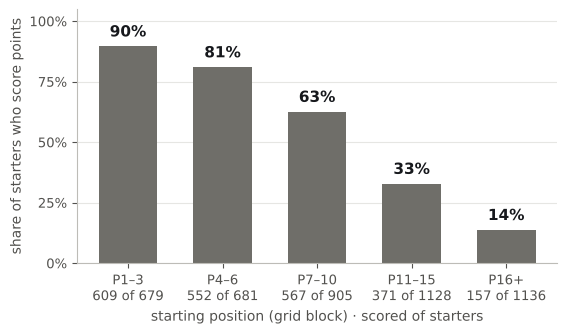

In [2]:
blocks = ["P1–3", "P4–6", "P7–10", "P11–15", "P16+"]
starters = [679, 681, 905, 1128, 1136]                      # starters per block (final_project, part 3.2)
scored = [609, 552, 567, 371, 157]
share = [s / n for s, n in zip(scored, starters)]
assert [round(x, 3) for x in share] == list(KEY["top10_by_block"].values())

vs.style()
fig, ax = plt.subplots(figsize=(6.2, 3.3))
x = np.arange(len(blocks))
ax.bar(x, share, 0.62, color=vs.NEUTRAL)
for i, (p, k, n) in enumerate(zip(share, scored, starters)):
    ax.text(i, p + 0.025, f"{p:.0%}", ha="center", va="bottom", fontsize=11, fontweight="bold", color=vs.INK)
ax.set_xticks(x, [f"{b}\n{k} of {n}" for b, k, n in zip(blocks, scored, starters)]); ax.set_ylim(0, 1.05); ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", visible=False)
ax.set_xlabel("starting position (grid block) · scored of starters"); ax.set_ylabel("share of starters who score points")
vs.save(fig, FIG, "C3_01_points_by_grid_block")

## 2. F1 by season: validation and test kept apart
Each season is predicted by a model trained only on earlier seasons. Rows are grouped by **stage** (validation, test)
and **rules**, which answers the C2 feedback about telling the evaluation seasons apart. Dots on a common zoomed
scale (no zero baseline needed for position marks); the right column gives model − grid rule.

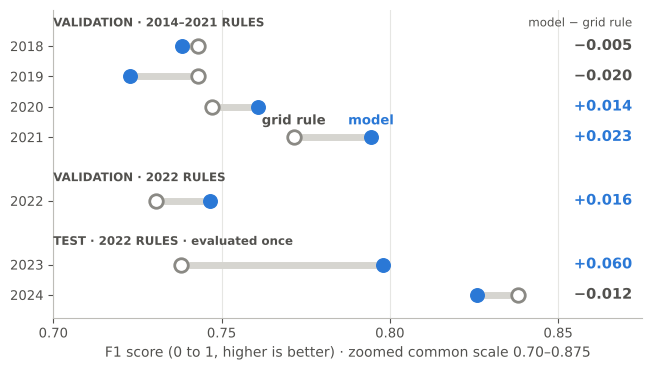

Model ahead in 4 of 7 seasons; largest gap +0.060


In [3]:
rows = [(int(r["season"]), r["F1 model"], r["F1 reference"]) for _, r in val.iterrows()] + \
       [(int(s), v[0], v[1]) for s, v in KEY["test_by_season"].items()]
groups = [("VALIDATION · 2014–2021 RULES", [2018, 2019, 2020, 2021]), ("VALIDATION · 2022 RULES", [2022]),
          ("TEST · 2022 RULES · evaluated once", [2023, 2024])]
f1 = {s: (m, r) for s, m, r in rows}

vs.style()
fig, ax = plt.subplots(figsize=(7.6, 4.0))
y, ypos, heads = 0, {}, []
for name, seasons in groups:
    heads.append((name, y)); y -= 0.75
    for s in seasons:
        ypos[s] = y; y -= 1
    y -= 0.35
for s, yy in ypos.items():
    m, r = f1[s]
    ax.plot([min(m, r), max(m, r)], [yy, yy], color=vs.LIGHT, lw=5, solid_capstyle="round", zorder=1)
    ax.scatter(r, yy, s=95, facecolor="white", edgecolor=vs.RULE, lw=2, zorder=3)
    ax.scatter(m, yy, s=95, color=vs.MODEL, zorder=3)
    d = m - r
    ax.text(0.872, yy, vs.minus(d), va="center", ha="right", fontsize=10.5, fontweight="bold",
            color=vs.MODEL if d > 0 else vs.INK2)
for name, yy in heads:
    ax.text(0.700, yy, name, fontsize=8.5, fontweight="bold", color=vs.INK2, va="center")
ax.text(0.872, heads[0][1], "model − grid rule", fontsize=8.5, color=vs.INK2, ha="right", va="center")
m21, r21 = f1[2021]
ax.text(m21, ypos[2021] + 0.42, "model", color=vs.MODEL, fontsize=9.5, fontweight="bold", ha="center")
ax.text(r21, ypos[2021] + 0.42, "grid rule", color=vs.INK2, fontsize=9.5, fontweight="bold", ha="center")
ax.set_yticks(list(ypos.values()), [str(s) for s in ypos]); ax.set_ylim(y + 0.6, 0.45)
ax.set_xlim(0.700, 0.875); ax.set_xticks([0.70, 0.75, 0.80, 0.85]); ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 score (0 to 1, higher is better) · zoomed common scale 0.70–0.875")
vs.save(fig, FIG, "C3_02_f1_by_season")
wins = sum(f1[s][0] > f1[s][1] for s in f1)
print(f"Model ahead in {wins} of {len(f1)} seasons; largest gap {vs.minus(max(m - r for m, r in f1.values()))}")

## 3. Errors on the test seasons (2023–2024, 919 driver-race rows, threshold 0.5)
The two error types the strategist cares about. Bars start at 0; the model is solid blue, the grid rule hatched grey; the
orange number is the difference (model − grid rule).

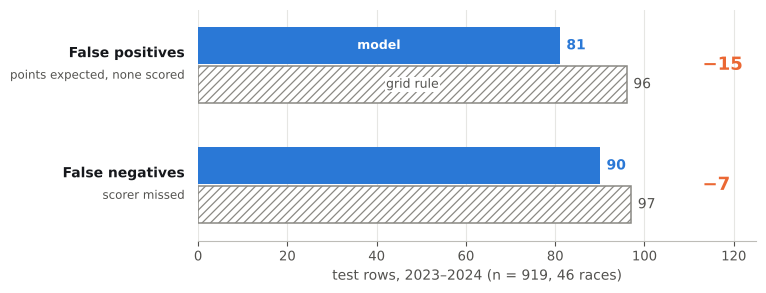

In [4]:
cm = KEY["test_cm"]
vs.style()
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for (k, lab, desc), yy in zip([("FP", "False positives", "points expected, none scored"),
                               ("FN", "False negatives", "scorer missed")], [1.3, 0.0]):
    vs.model_bar(ax, yy + 0.21, cm["model"][k], 0.4)
    vs.rule_bar(ax, yy - 0.21, cm["reference"][k], 0.4)
    ax.text(cm["model"][k] + 1.5, yy + 0.21, str(cm["model"][k]), va="center", color=vs.MODEL, fontweight="bold")
    ax.text(cm["reference"][k] + 1.5, yy - 0.21, str(cm["reference"][k]), va="center", color=vs.INK2)
    ax.text(-3, yy + 0.05, lab, ha="right", va="bottom", fontweight="bold", color=vs.INK)
    ax.text(-3, yy - 0.05, desc, ha="right", va="top", fontsize=8.5, color=vs.INK2)
    ax.text(113, yy, vs.minus(cm["model"][k] - cm["reference"][k], "{:+d}"), va="center", color=vs.ACCENT,
            fontweight="bold", fontsize=13)
ax.text(cm["model"]["FP"] / 2, 1.51, "model", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.text(cm["reference"]["FP"] / 2, 1.09, "grid rule", ha="center", va="center", color=vs.INK2, fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_yticks([]); ax.set_xlim(0, 125); ax.set_ylim(-0.6, 1.9); ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False); ax.set_xlabel(f"test rows, 2023–2024 (n = {KEY['test_rows']}, {KEY['test_races']} races)")
vs.save(fig, FIG, "C3_03_test_errors")

## 4. Where the model overrules the grid rule (test seasons)
Only the 102 of 919 test rows where the two approaches disagree. Length = rows (from 0); blue = the model was right,
hatched grey = the grid rule was right; the share and the group size are printed.

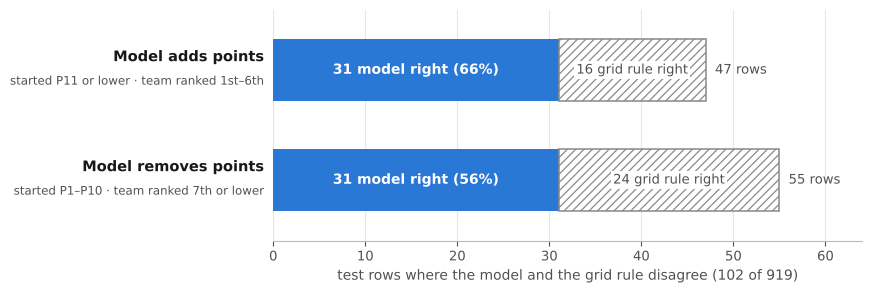

Model right in 62 of 102 (61%; race-bootstrap 95% interval 50%–72%)


In [5]:
vs.style()
fig, ax = plt.subplots(figsize=(7.6, 3.0))
items = [("Model adds points", "started P11 or lower · team ranked 1st–6th", KEY["up_right"], KEY["up"]),
         ("Model removes points", "started P1–P10 · team ranked 7th or lower", KEY["down_right"], KEY["down"])]
for (title, desc, right, n), yy in zip(items, [1.0, 0.0]):
    wrong = n - right
    vs.model_bar(ax, yy, right, 0.56)
    vs.rule_bar(ax, yy, wrong, 0.56, left=right)
    ax.text(right / 2, yy, f"{right} model right ({right / n:.0%})", ha="center", va="center", color="white",
            fontweight="bold", fontsize=10)
    ax.text(right + wrong / 2, yy, f"{wrong} grid rule right", ha="center", va="center", color=vs.INK2, fontsize=9.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.text(n + 1, yy, f"{n} rows", va="center", color=vs.INK2, fontsize=9.5)
    ax.text(-1, yy + 0.05, title, ha="right", va="bottom", fontweight="bold", color=vs.INK, fontsize=10.5)
    ax.text(-1, yy - 0.05, desc, ha="right", va="top", fontsize=8.5, color=vs.INK2)
ax.set_yticks([]); ax.set_xlim(0, 64); ax.set_ylim(-0.55, 1.55); ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"test rows where the model and the grid rule disagree ({KEY['disagree']} of {KEY['test_rows']})")
vs.save(fig, FIG, "C3_04_disagreements")
print(f"Model right in {KEY['disagree_right']} of {KEY['disagree']} "
      f"({KEY['disagree_right'] / KEY['disagree']:.0%}; race-bootstrap 95% interval {KEY['disagree_share_lo']:.0%}–{KEY['disagree_share_hi']:.0%})")

## 5. What each predicted season was trained on (walk-forward design)
One row per predicted season: light cells = seasons used for training, outlined cell = validation season, dark cell = test
season. Neutral colors, because this chart shows the design, not the model or the grid rule.

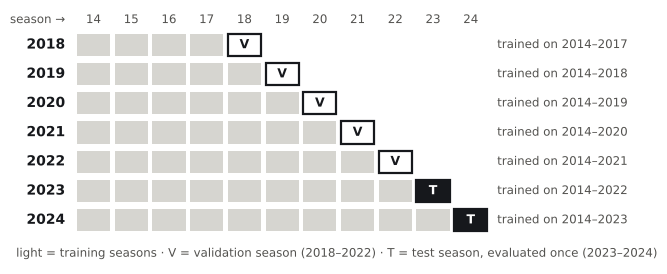

In [6]:
seasons = list(range(2014, 2025))
vs.style()
fig, ax = plt.subplots(figsize=(7.4, 3.3))
for i, target in enumerate(range(2018, 2025)):
    yy = -i
    for s in seasons:
        x = s - 2014
        if s < target:
            ax.add_patch(plt.Rectangle((x + 0.06, yy - 0.38), 0.88, 0.76, color=vs.LIGHT, lw=0))
        elif s == target:
            test = target >= 2023
            ax.add_patch(plt.Rectangle((x + 0.06, yy - 0.38), 0.88, 0.76, facecolor=vs.INK if test else "white",
                                       edgecolor=vs.INK, lw=1.6))
            ax.text(x + 0.5, yy, "T" if test else "V", ha="center", va="center", fontsize=9, fontweight="bold",
                    color="white" if test else vs.INK)
    ax.text(-0.25, yy, str(target), ha="right", va="center", fontsize=10, fontweight="bold",
            color=vs.INK)
    ax.text(11.2, yy, f"trained on 2014–{target - 1}", va="center", fontsize=8.5, color=vs.INK2)
for s in seasons:
    ax.text(s - 2014 + 0.5, 0.75, f"{s % 100:02d}", ha="center", fontsize=8.5, color=vs.INK2)
ax.text(-0.25, 0.75, "season →", ha="right", fontsize=8.5, color=vs.INK2)
ax.set_xlim(-1.6, 13.6); ax.set_ylim(-7.5, 1.2); ax.axis("off")
ax.text(-1.55, -7.25, "light = training seasons · V = validation season (2018–2022) · T = test season, evaluated once (2023–2024)",
        fontsize=8.5, color=vs.INK2)
vs.save(fig, FIG, "C3_05_season_design")

## 6. AI use
Claude (Anthropic) drafted the plotting code from the two W3 notebooks. We checked every value with the assertions in the
first code cell against `final_project.ipynb`, and reviewed each chart against the rules in `docs/decision_record.md`, part 3.